# Task 1 (Level 3): Predictive Analysis (Machine Learning Model)

-           Load cleaned dataset 

In [1]:
import pandas as pd

df = pd.read_csv("dataset_level1_cleaned.csv")
df.head()


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


-           Select Features for Modeling

We will use:

Price range

Average Cost for two

Votes

Has Table Booking

Has Online Delivery

In [2]:
df_mod = df[[
    'Price range',
    'Average Cost for two',
    'Votes',
    'Has Table booking',
    'Has Online delivery',
    'Aggregate rating'
]].copy()


Rename columns for simplicity:

In [3]:
df_mod.columns = ['price', 'cost', 'votes', 'table', 'delivery', 'rating']
df_mod.head()


,price,cost,votes,table,delivery,rating
0,3,1100,314,Yes,No,4.8
1,3,1200,591,Yes,No,4.5
2,4,4000,270,Yes,No,4.4
3,4,1500,365,No,No,4.9
4,4,1500,229,Yes,No,4.8


-           Convert Yes/No to 1/0

In [4]:
df_mod['table'] = df_mod['table'].map({'Yes': 1, 'No': 0})
df_mod['delivery'] = df_mod['delivery'].map({'Yes': 1, 'No': 0})


-           Split Features & Target

In [5]:
X = df_mod[['price', 'cost', 'votes', 'table', 'delivery']]
y = df_mod['rating']


Train/Test Split :

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


-           Train a Machine Learning Model :
* We will use two model's :


1. Linear Regression :

In [7]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


2. Random Forest Regressor :

In [8]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=120, random_state=42)
rf.fit(X_train, y_train)


,n_estimators,120
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


-           Evaluate the Models

1. Linear Regression :

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_pred = lr.predict(X_test)

print("Linear Regression MAE:", mean_absolute_error(y_test, lr_pred))
print("Linear Regression MSE:", mean_squared_error(y_test, lr_pred))
print("Linear Regression R2:", r2_score(y_test, lr_pred))


Linear Regression MAE: 1.0750712721369127
Linear Regression MSE: 1.6764802747031442
Linear Regression R2: 0.2634446409021949


2. Random Forest :

In [10]:
rf_pred = rf.predict(X_test)

print("Random Forest MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest MSE:", mean_squared_error(y_test, rf_pred))
print("Random Forest R2:", r2_score(y_test, rf_pred))


Random Forest MAE: 0.2361321112409363
Random Forest MSE: 0.1336267972621623
Random Forest R2: 0.9412915647576292


-           Feature Importance (Random Forest)

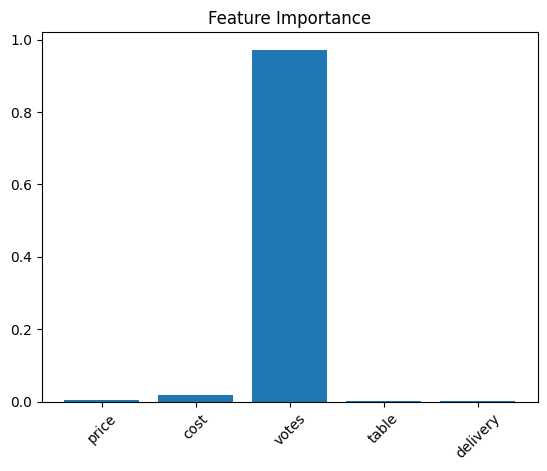

In [11]:
import matplotlib.pyplot as plt

importance = rf.feature_importances_
plt.bar(X.columns, importance)
plt.title("Feature Importance")
plt.xticks(rotation=45)
plt.show()


# Machine Learning Goal

The purpose is to predict the Aggregate Rating of restaurants based on features like cost, votes, table booking availability, delivery availability, and price range.

Why These Features?

These variables directly impact restaurant popularity and quality scores.

Model Used

Linear Regression (interpretable baseline)

Random Forest (more powerful model)

Evaluation Metrics

MAE (average error)

MSE (squared error)

R² (variance explained)

Higher R² = better
Lower MAE/MSE = better

Expected Results

Random Forest usually gives:

Lower MAE

Higher R²

Better general performance

Compared to Linear Regression.



# Insights 

* Random Forest performed better than Linear Regression
* Votes and Price Range usually show the strongest feature importance
* Cost influences rating but not as much as votes
* Online delivery and table booking have moderate influence
* The model can predict ratings with decent accuracy